<a href="https://colab.research.google.com/github/Heitorris/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/Atividade_2/Atividade_2_regress%C3%A3o_linear_com_v%C3%A1rias_vari%C3%A1veis_de_entrada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importação das bibliotecas

In [31]:
import io
import pathlib
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados e Leitura

In [32]:
from sklearn.datasets import fetch_california_housing
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares


## Exploração

In [33]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [34]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [35]:
y.head()

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


In [36]:
y.describe()

,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


| Variável | Significado |
|---|---|
| MedInc | Renda mediana dos domicílios da região. |
| HouseAge | Idade mediana dos imóveis da região, em anos. |
| AveRooms | Número médio de cômodos por domicílio. |
| AveBedrms | Número médio de quartos por domicílio. |
| Population | Número de habitantes da região. |
| AveOccup | Número médio de pessoas por domicílio. |
| Latitude | Latitude da região. |
| Longitude | Longitude da região. |
| MedHouseVal — saída y | Valor mediano dos imóveis, em unidades de US$ 100.000. |

In [37]:
# Criar uma cópia das entradas para a análise exploratória
df_analise = X.copy()

df_analise['Preco_USD'] = y * 100_000

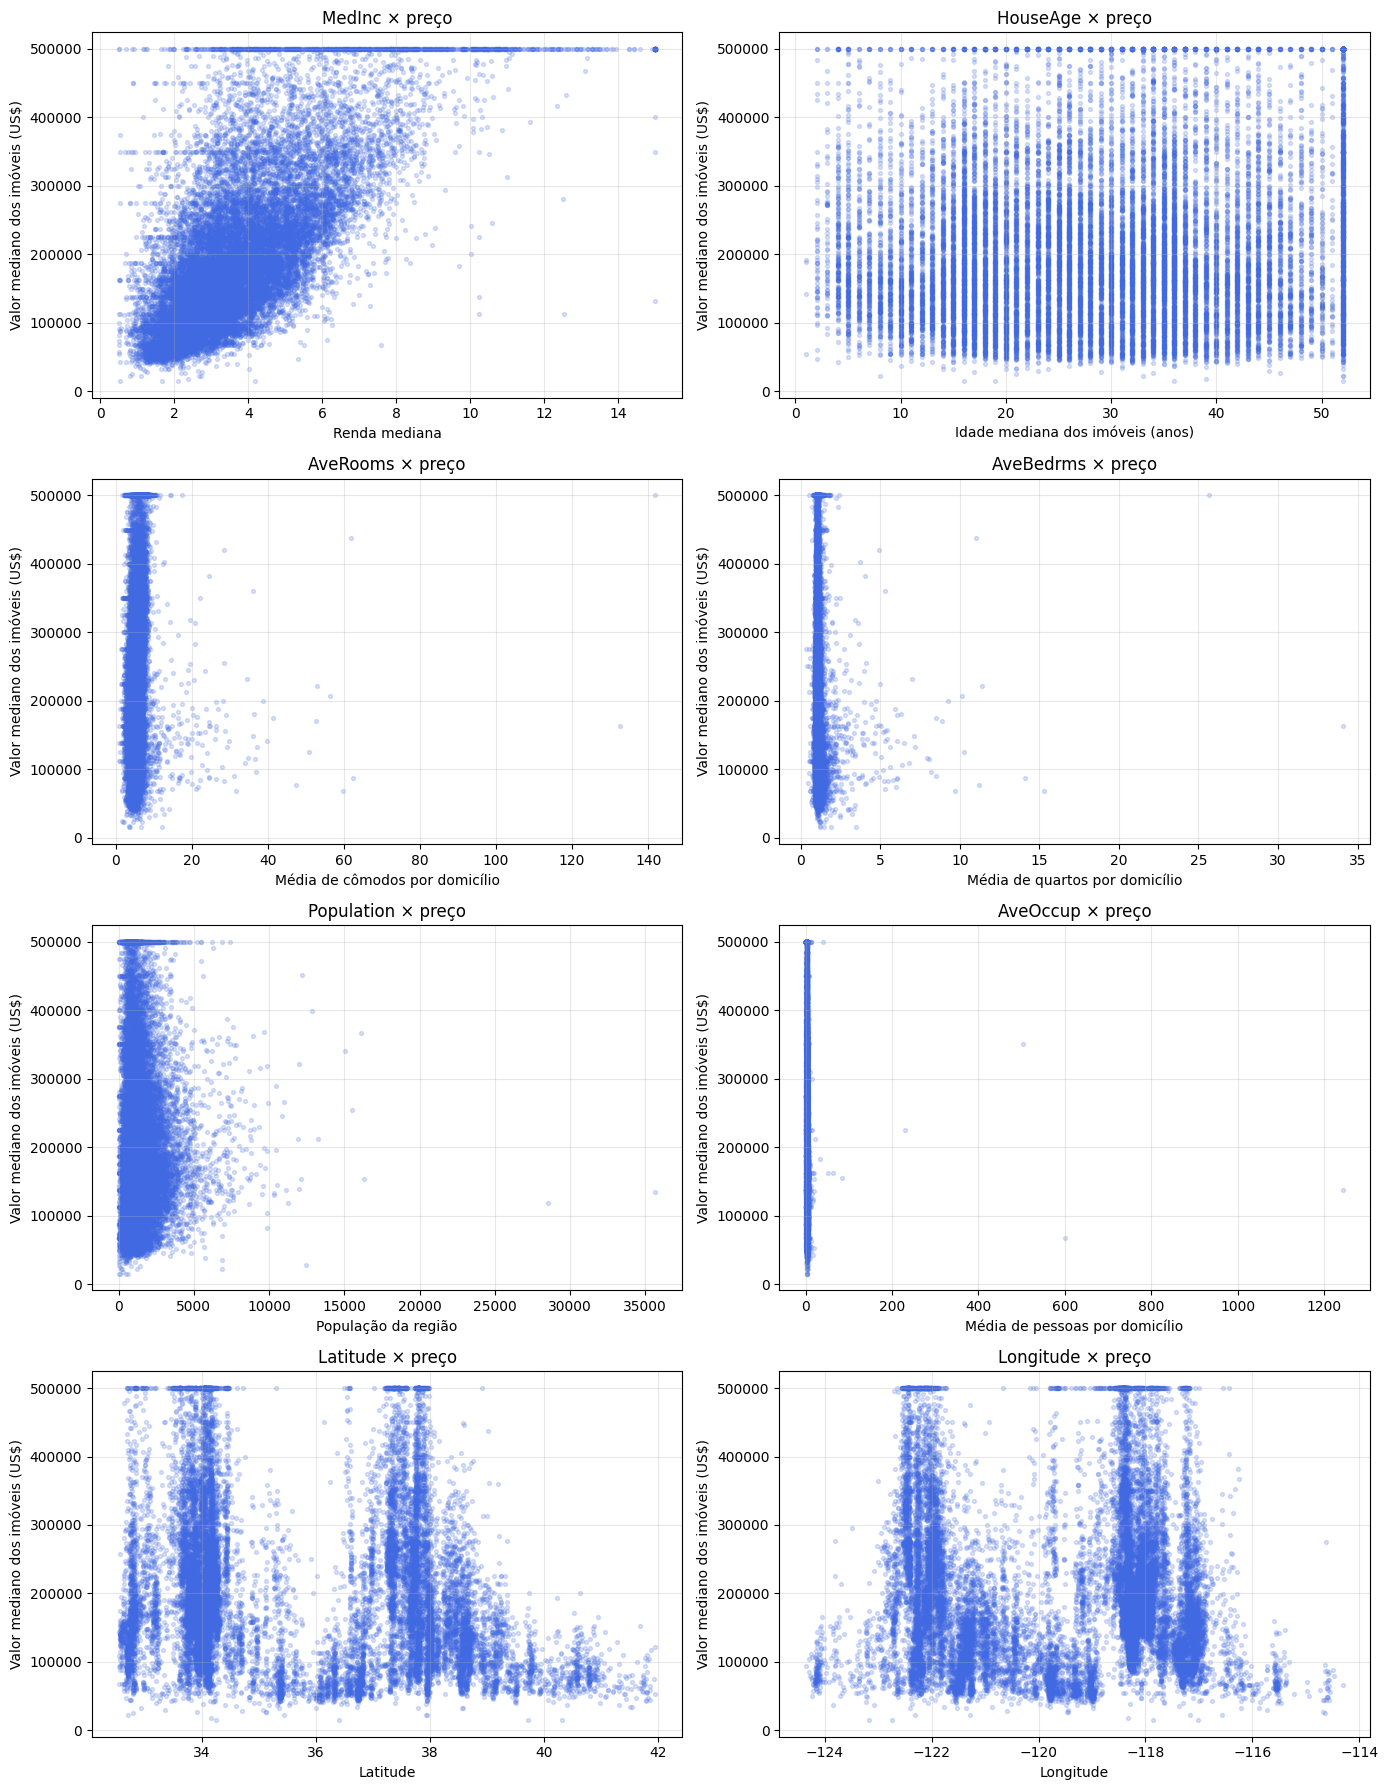

In [38]:

rotulos = {
    'MedInc': 'Renda mediana',
    'HouseAge': 'Idade mediana dos imóveis (anos)',
    'AveRooms': 'Média de cômodos por domicílio',
    'AveBedrms': 'Média de quartos por domicílio',
    'Population': 'População da região',
    'AveOccup': 'Média de pessoas por domicílio',
    'Latitude': 'Latitude',
    'Longitude': 'Longitude'
}

fig, eixos = plt.subplots(4, 2, figsize=(14, 18))

eixos = eixos.ravel()


for eixo, variavel in zip(eixos, X.columns):

    eixo.scatter(
        df_analise[variavel],
        df_analise['Preco_USD'],
        s=8,
        alpha=0.2,
        color='royalblue'
    )

    eixo.set_xlabel(rotulos[variavel])
    eixo.set_ylabel('Valor mediano dos imóveis (US$)')
    eixo.set_title(f'{variavel} × preço')

    eixo.ticklabel_format(
        axis='y',
        style='plain',
        useOffset=False
    )

    eixo.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Treino × validação

In [39]:
# Separar 70% para treino e 30% para validação + teste
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

In [40]:
# Dividi os 30% restantes em duas partes iguais:
# 15% da base para validação e 15% para teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)


In [41]:
print('Treino:    ', X_train.shape, y_train.shape)
print('Validação: ', X_val.shape, y_val.shape)
print('Teste:     ', X_test.shape, y_test.shape)

Treino:     (14448, 8) (14448,)
Validação:  (3096, 8) (3096,)
Teste:      (3096, 8) (3096,)


## Padronização

In [42]:
# Converter as saídas para matrizes com uma coluna
y_train_array = y_train.to_numpy().reshape(-1, 1)
y_val_array = y_val.to_numpy().reshape(-1, 1)
y_test_array = y_test.to_numpy().reshape(-1, 1)

In [43]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_scaler.fit(X_train)
y_scaler.fit(y_train_array)

StandardScaler()

In [44]:
# Padronizar as entradas dos três conjuntos
X_train_scaled = x_scaler.transform(X_train)
X_val_scaled = x_scaler.transform(X_val)
X_test_scaled = x_scaler.transform(X_test)

In [45]:
# Padronizar as saídas dos três conjuntos
y_train_scaled = y_scaler.transform(y_train_array)
y_val_scaled = y_scaler.transform(y_val_array)
y_test_scaled = y_scaler.transform(y_test_array)

In [46]:
pd.DataFrame(X_train_scaled, columns=X_train.columns).describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,1.444800e+04,1.444800e+04,1.444800e+04,1.444800e+04,1.444800e+04,1.444800e+04,1.444800e+04,1.444800e+04
mean,1.431118e-16,-5.557263e-17,-3.427798e-16,-1.475379e-16,6.688387e-17,1.204893e-17,-1.463822e-15,-3.241900e-15
std,1.000035e+00,1.000035e+00,1.000035e+00,1.000035e+00,1.000035e+00,1.000035e+00,1.000035e+00,1.000035e+00
min,-1.772846e+00,-2.186232e+00,-1.854194e+00,-1.708893e+00,-1.249733e+00,-1.961439e-01,-1.451850e+00,-2.379545e+00
25%,-6.875459e-01,-8.384372e-01,-4.031802e-01,-2.039186e-01,-5.586172e-01,-5.567326e-02,-8.009995e-01,-1.106366e+00
50%,-1.773331e-01,3.366524e-02,-8.384086e-02,-1.084759e-01,-2.279693e-01,-2.441482e-02,-6.464812e-01,5.362840e-01
75%,4.626017e-01,6.679216e-01,2.537482e-01,5.127834e-03,2.623017e-01,1.292294e-02,9.689383e-01,7.859269e-01
max,5.839437e+00,1.857152e+00,5.562333e+01,5.483640e+01,3.004254e+01,1.002338e+02,2.949583e+00,2.633284e+00


In [47]:
pd.DataFrame(X_val_scaled, columns=X_val.columns).describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000
mean,-0.021459,0.016354,-0.033347,-0.028014,0.001253,-0.015317,-0.056361,0.056337
std,0.973717,1.005364,0.731445,0.664798,1.043449,0.066632,0.998759,0.994618
min,-1.772846,-2.106950,-1.871612,-1.336439,-1.245347,-0.146364,-1.451850,-2.299659
25%,-0.687861,-0.838437,-0.413936,-0.210356,-0.569142,-0.056866,-0.815047,-1.012750
50%,-0.174288,0.033665,-0.089871,-0.112885,-0.238055,-0.024059,-0.679258,0.571234
75%,0.426181,0.667922,0.232204,-0.001038,0.233359,0.014512,0.950209,0.805898
max,5.839437,1.857152,12.864103,15.887804,13.047938,0.725738,2.874665,2.498477


In [48]:
pd.DataFrame(y_train_scaled, columns=[y_train.name]).describe()

,MedHouseVal
count,1.444800e+04
mean,-1.475379e-16
std,1.000035e+00
min,-1.658167e+00
25%,-7.570416e-01
50%,-2.386618e-01
75%,4.983016e-01
max,2.532087e+00


##Convertendo para tensores

In [49]:
X_train_tensor = torch.from_numpy(X_train_scaled).float()
X_val_tensor = torch.from_numpy(X_val_scaled).float()
X_test_tensor = torch.from_numpy(X_test_scaled).float()

In [50]:
y_train_tensor = torch.from_numpy(y_train_scaled).float()
y_val_tensor = torch.from_numpy(y_val_scaled).float()
y_test_tensor = torch.from_numpy(y_test_scaled).float()

In [51]:
print('X_train_tensor:', X_train_tensor.shape, ' y_train_tensor:', y_train_tensor.shape)
print('X_val_tensor:  ', X_val_tensor.shape, ' y_val_tensor:  ', y_val_tensor.shape)
print('X_test_tensor:  ', X_test_tensor.shape, ' y_val_tensor:  ', y_val_tensor.shape)

X_train_tensor: torch.Size([14448, 8])  y_train_tensor: torch.Size([14448, 1])
X_val_tensor:   torch.Size([3096, 8])  y_val_tensor:   torch.Size([3096, 1])
X_test_tensor:   torch.Size([3096, 8])  y_val_tensor:   torch.Size([3096, 1])


## Modelo

In [52]:
torch.manual_seed(1234)

model = nn.Linear(8, 1)

criterion = nn.MSELoss()

lr = 0.3
optimizer = optim.SGD(model.parameters(), lr=lr)

In [53]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [54]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [55]:
n_epochs = 120
train_losses = []
val_losses = []

for epoch in range(n_epochs):

    # Treinamento
    train_loss = train_epoch(
        model,
        optimizer,
        criterion,
        X_train_tensor,
        y_train_tensor
    )
    train_losses.append(train_loss)

    # Validação
    val_loss = validate_epoch(
        model,
        criterion,
        X_val_tensor,
        y_val_tensor
    )
    val_losses.append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f'Epoch[{epoch + 1}/{n_epochs}], '
            f'Train Loss: {train_loss:.6f}, '
            f'Val Loss: {val_loss:.6f}'
        )

Epoch[10/120], Train Loss: 0.421441, Val Loss: 0.430551
Epoch[20/120], Train Loss: 0.402168, Val Loss: 0.413673
Epoch[30/120], Train Loss: 0.394992, Val Loss: 0.407447
Epoch[40/120], Train Loss: 0.392304, Val Loss: 0.405145
Epoch[50/120], Train Loss: 0.391290, Val Loss: 0.404290
Epoch[60/120], Train Loss: 0.390904, Val Loss: 0.403969
Epoch[70/120], Train Loss: 0.390755, Val Loss: 0.403845
Epoch[80/120], Train Loss: 0.390696, Val Loss: 0.403794
Epoch[90/120], Train Loss: 0.390672, Val Loss: 0.403771
Epoch[100/120], Train Loss: 0.390662, Val Loss: 0.403759
Epoch[110/120], Train Loss: 0.390658, Val Loss: 0.403751
Epoch[120/120], Train Loss: 0.390656, Val Loss: 0.403746


##Avaliação

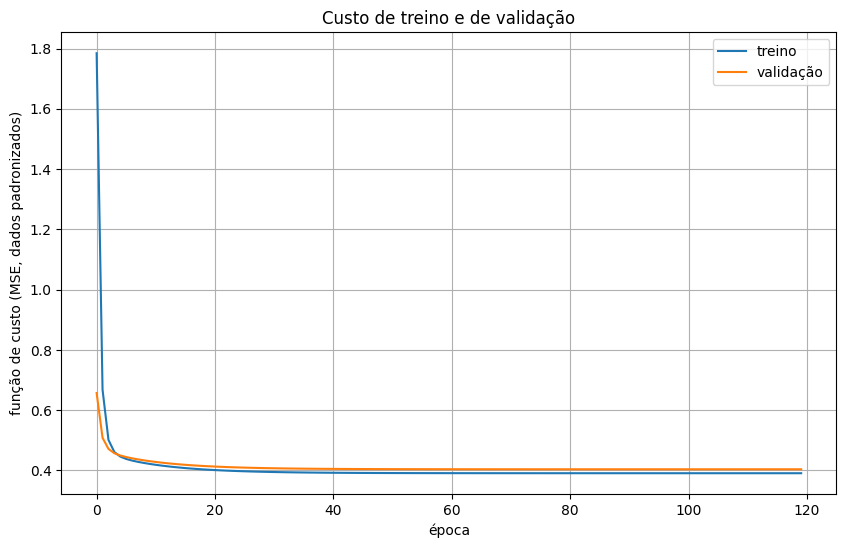

In [56]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

In [57]:
model.eval()

with torch.no_grad():
    y_pred_test = model(X_test_tensor)

# Desfazer a padronização das previsões
y_pred_test_original = y_scaler.inverse_transform(
    y_pred_test.numpy()
)

# Converter previsões e valores reais para dólares
# O y original está em unidades de US$ 100.000
y_pred_test_dolares = y_pred_test_original * 100_000
y_test_dolares = y_test_array * 100_000

# RMSE do modelo no teste
rmse_modelo = np.sqrt(
    np.mean((y_pred_test_dolares - y_test_dolares) ** 2)
)

In [58]:
# Média do preço calculada somente no treino
preco_medio_treino = y_train_array.mean() * 100_000

# Uma previsão constante para cada amostra de teste
y_pred_baseline = np.full(
    y_test_dolares.shape,
    preco_medio_treino
)

# RMSE do baseline no mesmo conjunto de teste
rmse_baseline = np.sqrt(
    np.mean((y_pred_baseline - y_test_dolares) ** 2)
)

print(f'Preço médio do treino: US$ {preco_medio_treino:,.2f}')
print(f'RMSE do modelo:        US$ {rmse_modelo:,.2f}')
print(f'RMSE do baseline:      US$ {rmse_baseline:,.2f}')

reducao_rmse = (1 - rmse_modelo / rmse_baseline) * 100
print(f'Redução do RMSE em relação ao baseline: {reducao_rmse:.2f}%')

Preço médio do treino: US$ 206,923.96
RMSE do modelo:        US$ 72,130.25
RMSE do baseline:      US$ 114,992.22
Redução do RMSE em relação ao baseline: 37.27%


In [59]:
# Extrair os oito pesos, sem o histórico de gradientes
pesos = model.weight.detach().numpy().reshape(-1)

# Associar cada peso à variável correspondente
tabela_pesos = pd.DataFrame({
    'Variável': X.columns,
    'Peso padronizado': pesos
})

# Ordenar do maior peso positivo ao mais negativo
tabela_pesos = tabela_pesos.sort_values(
    'Peso padronizado',
    ascending=False
)

display(tabela_pesos.round(4))

print(f'Bias: {model.bias.item():.6f}')

,Variável,Peso padronizado
0,MedInc,0.7346
3,AveBedrms,0.3017
1,HouseAge,0.1059
4,Population,-0.0006
5,AveOccup,-0.0361
2,AveRooms,-0.2600
7,Longitude,-0.7466
6,Latitude,-0.7683


Bias: 0.000000


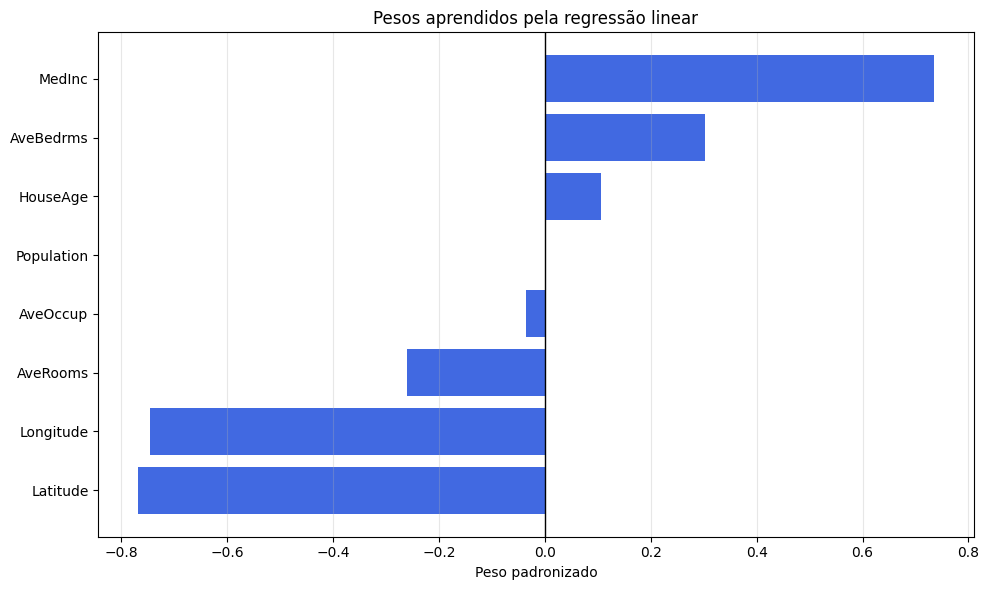

In [60]:
tabela_grafico = tabela_pesos.sort_values('Peso padronizado')

plt.figure(figsize=(10, 6))
plt.barh(
    tabela_grafico['Variável'],
    tabela_grafico['Peso padronizado'],
    color='royalblue'
)

plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Peso padronizado')
plt.title('Pesos aprendidos pela regressão linear')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

`Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto?`

É visto no grafico anterior que as variaveis que aumentão o preço são: *Medinc*  *AveBedrms* e *HauseAge* e as que diminuem *AveRooms*, *Longitude* e *Latitude* e a variavel *Population* não teve valor significativo logo sendo indiferente na predição do moelo para o preço da casa.

`Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?`


A padronização permite comparar as magnitudes dos pesos porque uma
unidade em qualquer entrada padronizada representa um desvio padrão
da variável original. Como a saída também foi padronizada, cada peso
representa a mudança prevista em desvios padrão do preço para esse
aumento da entrada, mantendo as demais constantes.

Sem padronização, os pesos corresponderiam a unidades diferentes,
como habitantes, cômodos e graus de latitude, tornando a comparação
direta inadequada.

## Conclusão


A regressão linear apresentou RMSE de US$ 72.130,25 no teste, reduzindo
o erro em 37,27% em relação ao baseline da média. O modelo é útil como
uma primeira aproximação, mas o erro ainda é elevado para estimativas
precisas de preços. Para melhorar, primeiro realizaria um tratamento nos dados para investigar os outliers das variaveis `AveOccup` e `AveRooms` se esses valores estão causando algum problema no treinamento do modelo geral,
criaria relações não lineares e interações entre variáveis e compararia
outros modelos, usando a validação para escolher as configurações.